## BaseLine models

In [1]:
import sys
from pathlib import Path

import torch
from torch import nn

PROJECT_ROOT = Path(
    "/home/adarsha/projects/"
    "Household-Animals-Classification-Using-Deep-Learning"
)

assert (PROJECT_ROOT / "scripts" / "models.py").is_file()

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from scripts.models import VGG6

if not torch.cuda.is_available():
    raise RuntimeError("CUDA is unavailable in the selected notebook kernel.")

device = torch.device("cuda")

print("Project:", PROJECT_ROOT)
print("GPU:", torch.cuda.get_device_name(0))

Project: /home/adarsha/projects/Household-Animals-Classification-Using-Deep-Learning
GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU


## Construct and inspect VGG-6

In [2]:
torch.manual_seed(42)
torch.cuda.manual_seed_all(42)

model = VGG6(
    image_size=224,
    hidden_units=512,
    dropout=0.0,
).to(device)

print(model)
print(
    "\nTrainable parameters:",
    f"{sum(p.numel() for p in model.parameters() if p.requires_grad):,}",
)

VGG6(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=25088, out_features=512, bias=True)
    (2): ReLU()
    (3): Linear(in_features=512, out_features=1, bias=True)
  )
)

Trainable parameters: 13,086,913


## Verify forward and backward computation

In [4]:
criterion = nn.BCEWithLogitsLoss()

dummy_images = torch.randn(2, 3, 224, 224, device=device)
dummy_labels = torch.tensor([0.0, 1.0], device=device)

model.train()
model.zero_grad(set_to_none=True)

logits = model(dummy_images)
loss = criterion(logits, dummy_labels)
loss.backward()

assert logits.shape == (2,)
assert torch.isfinite(loss).item()

for name, parameter in model.named_parameters():
    assert parameter.grad is not None, f"Missing gradient: {name}"
    assert torch.isfinite(parameter.grad).all().item(), (
        f"Non-finite gradient: {name}"
    )

print("Output shape:", logits.shape)
print("Loss:", loss.item())
print("Forward and backward checks passed.")

# Clear diagnostic gradients before actual training.
model.zero_grad(set_to_none=True)
del dummy_images, dummy_labels, logits, loss

Output shape: torch.Size([2])
Loss: 0.6934037208557129
Forward and backward checks passed.


## Configure the experiment

In [7]:
import csv
import hashlib
import json
import time

from tqdm.auto import tqdm
from scripts.data import make_loaders, MEAN, STD

SEED = 42
EPOCHS = 20
BATCH_SIZE = 32
LEARNING_RATE = 1e-4

RUN_DIR = PROJECT_ROOT / "outputs" / "vgg6_initial"

if RUN_DIR.exists() and any(RUN_DIR.iterdir()):
    raise RuntimeError(
        "outputs/vgg6_initial already contains an experiment. "
        "Choose a new RUN_DIR to avoid overwriting it."
    )

train_loader, val_loader, _ = make_loaders(
    batch_size=BATCH_SIZE,
    num_workers=0,
    seed=SEED,
    augment_train=False,
)

torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Fresh model: the earlier diagnostic computation is not training.
model = VGG6(
    image_size=224,
    hidden_units=512,
    dropout=0.0,
).to(device)

criterion = nn.BCEWithLogitsLoss()

optimizer = torch.optim.RMSprop(
    model.parameters(),
    lr=LEARNING_RATE,
    alpha=0.99,
    eps=1e-8,
    momentum=0.0,
    weight_decay=0.0,
)

# Full precision for this initial experiment.
# Mixed precision can be added as a documented execution change later.

RUN_DIR.mkdir(parents=True, exist_ok=True)

config = {
    "experiment": "vgg6_initial",
    "seed": SEED,
    "epochs": EPOCHS,
    "batch_size": BATCH_SIZE,
    "image_size": 224,
    "hidden_units": 512,
    "dropout": 0.0,
    "augmentation": False,
    "optimizer": "RMSprop",
    "learning_rate": LEARNING_RATE,
    "alpha": 0.99,
    "eps": 1e-8,
    "momentum": 0.0,
    "weight_decay": 0.0,
    "loss": "BCEWithLogitsLoss",
    "normalization_mean": list(MEAN),
    "normalization_std": list(STD),
    "label_mapping": {"cat": 0, "dog": 1},
    "precision": "float32",
    "checkpoint_selection": "lowest validation loss",
    "torch_version": str(torch.__version__),
    "gpu": torch.cuda.get_device_name(0),
    "split_manifest_sha256": {
        split: hashlib.sha256(
            (
                PROJECT_ROOT / "data" / "splits" / f"{split}.csv"
            ).read_bytes()
        ).hexdigest()
        for split in ("train", "val", "test")
    },
}

(RUN_DIR / "config.json").write_text(
    json.dumps(config, indent=2),
    encoding="utf-8",
)

print("Experiment:", config["experiment"])
print("Training images:", len(train_loader.dataset))
print("Validation images:", len(val_loader.dataset))
print("Augmentation: OFF | Dropout: OFF")
print("Outputs:", RUN_DIR)

Experiment: vgg6_initial
Training images: 19994
Validation images: 3998
Augmentation: OFF | Dropout: OFF
Outputs: /home/adarsha/projects/Household-Animals-Classification-Using-Deep-Learning/outputs/vgg6_initial


## Define one epoch

In [8]:
def run_epoch(loader, training):
    model.train(training)

    total_loss = 0.0
    total_correct = 0
    total_images = 0

    progress = tqdm(
        loader,
        desc="Training" if training else "Validation",
        leave=False,
    )

    for images, labels in progress:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        # Binary loss requires floating-point targets.
        targets = labels.float()

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            logits = model(images)
            loss = criterion(logits, targets)

            if not torch.isfinite(loss).item():
                raise RuntimeError("Non-finite loss detected.")

            if training:
                loss.backward()
                optimizer.step()

        batch_size = labels.size(0)
        predictions = (logits.detach() >= 0).long()

        total_images += batch_size
        total_loss += loss.detach().item() * batch_size
        total_correct += (predictions == labels).sum().item()

        progress.set_postfix(
            loss=f"{total_loss / total_images:.4f}",
            accuracy=f"{total_correct / total_images:.2%}",
        )

    return {
        "loss": total_loss / total_images,
        "accuracy": total_correct / total_images,
    }

## Train and save checkpoints

In [9]:
history = []
best_val_loss = float("inf")

for epoch in range(1, EPOCHS + 1):
    started = time.perf_counter()

    train_metrics = run_epoch(train_loader, training=True)
    val_metrics = run_epoch(val_loader, training=False)

    row = {
        "epoch": epoch,
        "train_loss": train_metrics["loss"],
        "train_accuracy": train_metrics["accuracy"],
        "val_loss": val_metrics["loss"],
        "val_accuracy": val_metrics["accuracy"],
        "seconds": time.perf_counter() - started,
    }
    history.append(row)

    with (RUN_DIR / "history.csv").open(
        "w", newline="", encoding="utf-8"
    ) as file:
        writer = csv.DictWriter(file, fieldnames=list(row))
        writer.writeheader()
        writer.writerows(history)

    improved = row["val_loss"] < best_val_loss
    if improved:
        best_val_loss = row["val_loss"]

    checkpoint = {
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "epoch": epoch,
        "best_val_loss": best_val_loss,
        "val_loss": row["val_loss"],
        "val_accuracy": row["val_accuracy"],
        "config": config,
    }

    torch.save(checkpoint, RUN_DIR / "last.pt")

    if improved:
        torch.save(checkpoint, RUN_DIR / "best.pt")

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"Train loss: {row['train_loss']:.4f}, "
        f"accuracy: {row['train_accuracy']:.2%} | "
        f"Val loss: {row['val_loss']:.4f}, "
        f"accuracy: {row['val_accuracy']:.2%} | "
        f"Time: {row['seconds']:.0f}s"
        + (" | Best checkpoint saved" if improved else ""),
        flush=True,
    )

print("\nInitial baseline training completed.")

Epoch 01/20 | Train loss: 0.5617, accuracy: 70.14% | Val loss: 0.4943, accuracy: 75.64% | Time: 104s | Best checkpoint saved


Epoch 02/20 | Train loss: 0.4641, accuracy: 78.00% | Val loss: 0.4822, accuracy: 76.59% | Time: 102s | Best checkpoint saved


Epoch 03/20 | Train loss: 0.4081, accuracy: 81.59% | Val loss: 0.4191, accuracy: 81.42% | Time: 103s | Best checkpoint saved


Epoch 04/20 | Train loss: 0.3647, accuracy: 83.79% | Val loss: 0.3655, accuracy: 83.97% | Time: 100s | Best checkpoint saved


Epoch 05/20 | Train loss: 0.3210, accuracy: 85.95% | Val loss: 0.3588, accuracy: 84.44% | Time: 102s | Best checkpoint saved


...

Epoch 16/20 | Train loss: 0.0277, accuracy: 99.24% | Val loss: 0.8387, accuracy: 82.87% | Time: 104s


Epoch 17/20 | Train loss: 0.0277, accuracy: 99.27% | Val loss: 0.5747, accuracy: 86.27% | Time: 103s


Epoch 18/20 | Train loss: 0.0257, accuracy: 99.42% | Val loss: 0.6219, accuracy: 86.54% | Time: 103s


Epoch 19/20 | Train loss: 0.0224, accuracy: 99.43% | Val loss: 0.7224, accuracy: 86.24% | Time: 103s


Epoch 20/20 | Train loss: 0.0159, accuracy: 99.59% | Val loss: 0.7211, accuracy: 86.17% | Time: 103s

Initial baseline training completed.


## Plot the learning curves

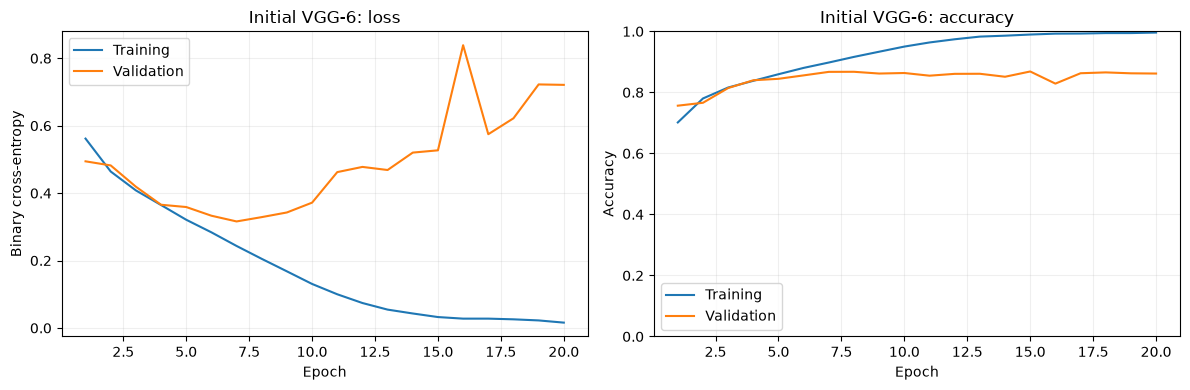

In [10]:
import matplotlib.pyplot as plt

curve_dir = (
    PROJECT_ROOT / "outputs" / "vgg6_initial"
)

with (curve_dir / "history.csv").open(
    newline="", encoding="utf-8"
) as file:
    records = list(csv.DictReader(file))

epochs = [int(row["epoch"]) for row in records]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for prefix, label in [
    ("train", "Training"),
    ("val", "Validation"),
]:
    axes[0].plot(
        epochs,
        [float(row[f"{prefix}_loss"]) for row in records],
        label=label,
    )
    axes[1].plot(
        epochs,
        [float(row[f"{prefix}_accuracy"]) for row in records],
        label=label,
    )

axes[0].set_title("Initial VGG-6: loss")
axes[0].set_ylabel("Binary cross-entropy")

axes[1].set_title("Initial VGG-6: accuracy")
axes[1].set_ylabel("Accuracy")
axes[1].set_ylim(0, 1)

for ax in axes:
    ax.set_xlabel("Epoch")
    ax.legend()
    ax.grid(alpha=0.2)

fig.tight_layout()
fig.savefig(curve_dir / "learning_curves.png", dpi=150)
plt.show()

## Configure regularized VGG-6

In [11]:
import csv
import json
import time

import torch
from torch import nn
from scripts.data import make_loaders
from scripts.models import VGG6

INITIAL_DIR = PROJECT_ROOT / "outputs" / "vgg6_initial"
RUN_DIR = PROJECT_ROOT / "outputs" / "vgg6_regularized"

if RUN_DIR.exists() and any(RUN_DIR.iterdir()):
    raise RuntimeError(
        "outputs/vgg6_regularized already contains an experiment. "
        "Choose another RUN_DIR to avoid overwriting it."
    )

# Reuse recorded settings from the initial experiment.
config = json.loads(
    (INITIAL_DIR / "config.json").read_text(encoding="utf-8")
)
config.update({
    "experiment": "vgg6_regularized",
    "dropout": 0.5,
    "augmentation": True,
    "augmentation_settings": {
        "horizontal_flip_probability": 0.5,
        "rotation_degrees": 10,
    },
})

SEED = config["seed"]
EPOCHS = config["epochs"]

train_loader, val_loader, _ = make_loaders(
    batch_size=config["batch_size"],
    num_workers=0,
    seed=SEED,
    augment_train=True,
)

# Start from scratch, using the same initialization seed.
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda")

model = VGG6(
    image_size=config["image_size"],
    hidden_units=config["hidden_units"],
    dropout=config["dropout"],
).to(device)

criterion = nn.BCEWithLogitsLoss()

optimizer = torch.optim.RMSprop(
    model.parameters(),
    lr=config["learning_rate"],
    alpha=config["alpha"],
    eps=config["eps"],
    momentum=config["momentum"],
    weight_decay=config["weight_decay"],
)

RUN_DIR.mkdir(parents=True, exist_ok=True)
(RUN_DIR / "config.json").write_text(
    json.dumps(config, indent=2),
    encoding="utf-8",
)

assert train_loader.dataset.augmentation_enabled
assert not val_loader.dataset.augmentation_enabled

print("Experiment:", config["experiment"])
print("Dropout:", config["dropout"])
print("Training augmentation: ON")
print("Validation augmentation: OFF")
print("Epochs:", EPOCHS)
print("Outputs:", RUN_DIR)

Experiment: vgg6_regularized
Dropout: 0.5
Training augmentation: ON
Validation augmentation: OFF
Epochs: 20
Outputs: /home/adarsha/projects/Household-Animals-Classification-Using-Deep-Learning/outputs/vgg6_regularized


## Train regularized VGG-6

In [12]:
history = []
best_val_loss = float("inf")

for epoch in range(1, EPOCHS + 1):
    started = time.perf_counter()

    train_metrics = run_epoch(train_loader, training=True)
    val_metrics = run_epoch(val_loader, training=False)

    row = {
        "epoch": epoch,
        "train_loss": train_metrics["loss"],
        "train_accuracy": train_metrics["accuracy"],
        "val_loss": val_metrics["loss"],
        "val_accuracy": val_metrics["accuracy"],
        "seconds": time.perf_counter() - started,
    }
    history.append(row)

    with (RUN_DIR / "history.csv").open(
        "w", newline="", encoding="utf-8"
    ) as file:
        writer = csv.DictWriter(file, fieldnames=list(row))
        writer.writeheader()
        writer.writerows(history)

    improved = row["val_loss"] < best_val_loss

    if improved:
        best_val_loss = row["val_loss"]

    checkpoint = {
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "epoch": epoch,
        "best_val_loss": best_val_loss,
        "val_loss": row["val_loss"],
        "val_accuracy": row["val_accuracy"],
        "config": config,
    }

    torch.save(checkpoint, RUN_DIR / "last.pt")

    if improved:
        torch.save(checkpoint, RUN_DIR / "best.pt")

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"Train loss: {row['train_loss']:.4f}, "
        f"accuracy: {row['train_accuracy']:.2%} | "
        f"Val loss: {row['val_loss']:.4f}, "
        f"accuracy: {row['val_accuracy']:.2%} | "
        f"Time: {row['seconds']:.0f}s"
        + (" | Best checkpoint saved" if improved else ""),
        flush=True,
    )

print("\nRegularized VGG-6 training completed.")

Epoch 01/20 | Train loss: 0.5837, accuracy: 68.09% | Val loss: 0.5145, accuracy: 74.71% | Time: 103s | Best checkpoint saved


Epoch 02/20 | Train loss: 0.4949, accuracy: 76.05% | Val loss: 0.4730, accuracy: 77.66% | Time: 105s | Best checkpoint saved


Epoch 03/20 | Train loss: 0.4465, accuracy: 78.87% | Val loss: 0.4314, accuracy: 80.77% | Time: 106s | Best checkpoint saved


Epoch 04/20 | Train loss: 0.4103, accuracy: 81.32% | Val loss: 0.3847, accuracy: 83.27% | Time: 106s | Best checkpoint saved


Epoch 05/20 | Train loss: 0.3785, accuracy: 83.23% | Val loss: 0.3871, accuracy: 82.32% | Time: 105s


...

Epoch 16/20 | Train loss: 0.1816, accuracy: 92.43% | Val loss: 0.2261, accuracy: 91.27% | Time: 106s | Best checkpoint saved


Epoch 17/20 | Train loss: 0.1716, accuracy: 92.87% | Val loss: 0.2963, accuracy: 88.14% | Time: 105s


Epoch 18/20 | Train loss: 0.1590, accuracy: 93.64% | Val loss: 0.2150, accuracy: 91.37% | Time: 105s | Best checkpoint saved


Epoch 19/20 | Train loss: 0.1531, accuracy: 93.87% | Val loss: 0.2059, accuracy: 91.70% | Time: 107s | Best checkpoint saved


Epoch 20/20 | Train loss: 0.1430, accuracy: 94.33% | Val loss: 0.2100, accuracy: 92.10% | Time: 104s

Regularized VGG-6 training completed.


## Compare both experiments

Initial: selected epoch 7 | Validation loss 0.3160 | Validation accuracy 86.72%
Regularized: selected epoch 19 | Validation loss 0.2059 | Validation accuracy 91.70%


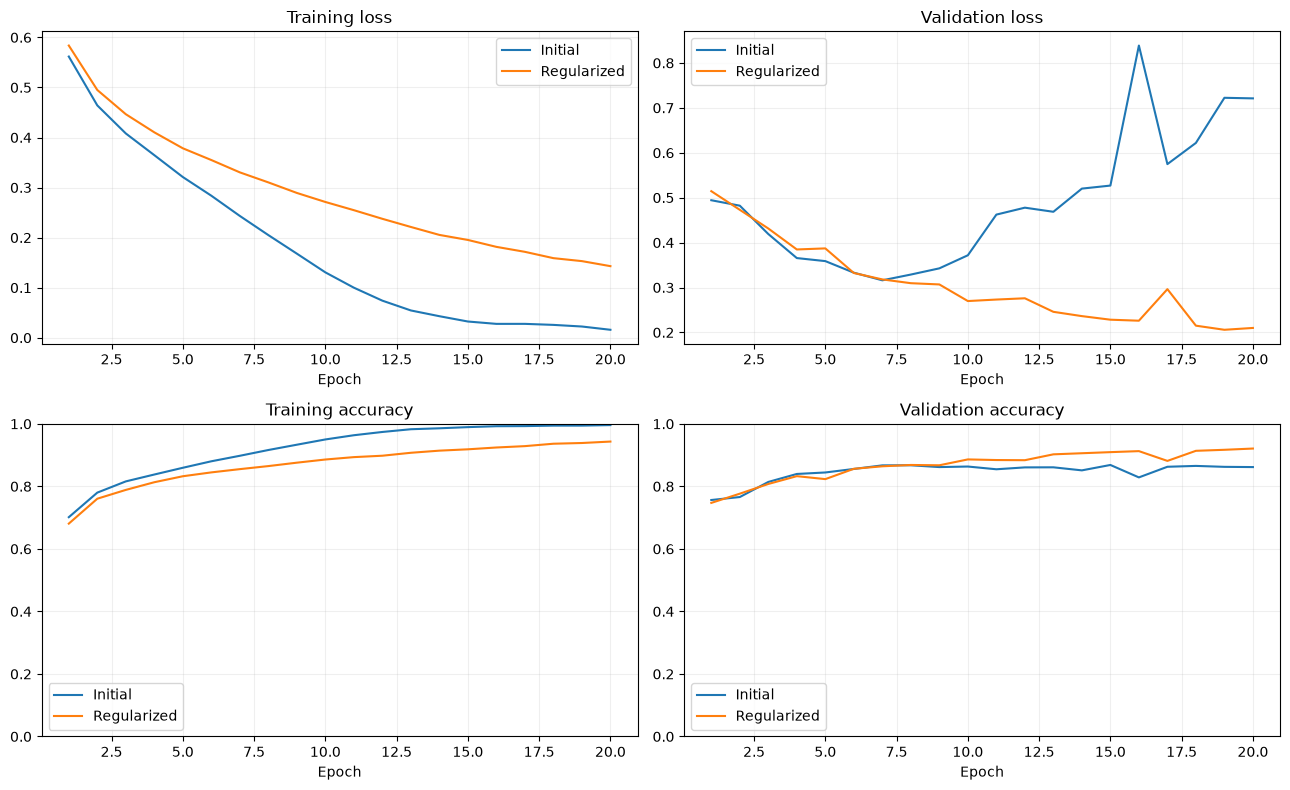

Saved: /home/adarsha/projects/Household-Animals-Classification-Using-Deep-Learning/outputs/vgg6_comparison.png


In [13]:
import matplotlib.pyplot as plt

experiments = {
    "Initial": PROJECT_ROOT / "outputs" / "vgg6_initial",
    "Regularized": PROJECT_ROOT / "outputs" / "vgg6_regularized",
}

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
colors = {"Initial": "tab:blue", "Regularized": "tab:orange"}

panels = [
    ("train_loss", "Training loss", axes[0, 0]),
    ("val_loss", "Validation loss", axes[0, 1]),
    ("train_accuracy", "Training accuracy", axes[1, 0]),
    ("val_accuracy", "Validation accuracy", axes[1, 1]),
]

for name, directory in experiments.items():
    with (directory / "history.csv").open(
        newline="", encoding="utf-8"
    ) as file:
        records = list(csv.DictReader(file))

    epochs = [int(row["epoch"]) for row in records]

    for metric, title, ax in panels:
        ax.plot(
            epochs,
            [float(row[metric]) for row in records],
            label=name,
            color=colors[name],
        )

    best = min(records, key=lambda row: float(row["val_loss"]))

    print(
        f"{name}: selected epoch {best['epoch']} | "
        f"Validation loss {float(best['val_loss']):.4f} | "
        f"Validation accuracy {float(best['val_accuracy']):.2%}"
    )

for metric, title, ax in panels:
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.legend()
    ax.grid(alpha=0.2)

    if "accuracy" in metric:
        ax.set_ylim(0, 1)

fig.tight_layout()

comparison_path = (
    PROJECT_ROOT / "outputs" / "vgg6_comparison.png"
)
fig.savefig(comparison_path, dpi=150)
plt.show()

print("Saved:", comparison_path)

## Configure frozen VGG-16

In [14]:
import importlib
import json
import torch
from torch import nn

import scripts.models as models_module
from scripts.data import make_loaders

importlib.reload(models_module)
VGG16Binary = models_module.VGG16Binary

RUN_DIR = PROJECT_ROOT / "outputs" / "vgg16_frozen"

if RUN_DIR.exists() and any(RUN_DIR.iterdir()):
    raise RuntimeError(
        "outputs/vgg16_frozen already contains an experiment. "
        "Choose another RUN_DIR to avoid overwriting it."
    )

config = json.loads(
    (
        PROJECT_ROOT
        / "outputs"
        / "vgg6_regularized"
        / "config.json"
    ).read_text(encoding="utf-8")
)

config.update({
    "experiment": "vgg16_frozen",
    "model": "VGG16Binary",
    "pretrained_weights": "VGG16_Weights.IMAGENET1K_V1",
    "feature_extractor_frozen": True,
    "hidden_units": 512,
    "dropout": 0.5,
    "epochs": 20,
    "learning_rate": 1e-4,
})

EPOCHS = config["epochs"]
SEED = config["seed"]

train_loader, val_loader, _ = make_loaders(
    batch_size=config["batch_size"],
    num_workers=0,
    seed=SEED,
    augment_train=True,
)

torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda")

# Release the previous experiment's in-memory model and optimizer.
# Its saved checkpoints remain available.
del optimizer, model
torch.cuda.empty_cache()

model = VGG16Binary(
    hidden_units=config["hidden_units"],
    dropout=config["dropout"],
    pretrained=True,
).to(device)

criterion = nn.BCEWithLogitsLoss()

optimizer = torch.optim.RMSprop(
    [p for p in model.parameters() if p.requires_grad],
    lr=config["learning_rate"],
    alpha=config["alpha"],
    eps=config["eps"],
    momentum=config["momentum"],
    weight_decay=config["weight_decay"],
)

RUN_DIR.mkdir(parents=True, exist_ok=True)
(RUN_DIR / "config.json").write_text(
    json.dumps(config, indent=2),
    encoding="utf-8",
)

frozen_count = sum(
    p.numel() for p in model.parameters() if not p.requires_grad
)
trainable_count = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print("Frozen parameters:", f"{frozen_count:,}")
print("Trainable parameters:", f"{trainable_count:,}")
print("Outputs:", RUN_DIR)

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /home/adarsha/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 528M/528M [00:18<00:00, 29.4MB/s]


Frozen parameters: 14,714,688
Trainable parameters: 12,846,081
Outputs: /home/adarsha/projects/Household-Animals-Classification-Using-Deep-Learning/outputs/vgg16_frozen


## Verify the freeze and output shape

In [15]:
assert all(
    not p.requires_grad for p in model.features.parameters()
)
assert all(
    p.requires_grad for p in model.classifier.parameters()
)

check_images, _ = next(iter(val_loader))

model.eval()
with torch.no_grad():
    check_logits = model(check_images[:2].to(device))

assert check_logits.shape == (2,)
assert torch.isfinite(check_logits).all().item()

print("Convolutional layers: FROZEN")
print("New classifier: TRAINABLE")
print("Output shape:", check_logits.shape)
print("Transfer-learning setup passed.")

del check_images, check_logits

Convolutional layers: FROZEN
New classifier: TRAINABLE
Output shape: torch.Size([2])
Transfer-learning setup passed.


## Train the new classifier

In [16]:
import csv
import time

history = []
best_val_loss = float("inf")

for epoch in range(1, EPOCHS + 1):
    started = time.perf_counter()

    train_metrics = run_epoch(train_loader, training=True)
    val_metrics = run_epoch(val_loader, training=False)

    row = {
        "epoch": epoch,
        "train_loss": train_metrics["loss"],
        "train_accuracy": train_metrics["accuracy"],
        "val_loss": val_metrics["loss"],
        "val_accuracy": val_metrics["accuracy"],
        "seconds": time.perf_counter() - started,
    }
    history.append(row)

    with (RUN_DIR / "history.csv").open(
        "w", newline="", encoding="utf-8"
    ) as file:
        writer = csv.DictWriter(file, fieldnames=list(row))
        writer.writeheader()
        writer.writerows(history)

    improved = row["val_loss"] < best_val_loss
    if improved:
        best_val_loss = row["val_loss"]

    checkpoint = {
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "epoch": epoch,
        "best_val_loss": best_val_loss,
        "val_loss": row["val_loss"],
        "val_accuracy": row["val_accuracy"],
        "config": config,
    }

    torch.save(checkpoint, RUN_DIR / "last.pt")

    if improved:
        torch.save(checkpoint, RUN_DIR / "best.pt")

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"Train loss: {row['train_loss']:.4f}, "
        f"accuracy: {row['train_accuracy']:.2%} | "
        f"Val loss: {row['val_loss']:.4f}, "
        f"accuracy: {row['val_accuracy']:.2%} | "
        f"Time: {row['seconds']:.0f}s"
        + (" | Best checkpoint saved" if improved else ""),
        flush=True,
    )

print("\nFrozen VGG-16 training completed.")

Epoch 01/20 | Train loss: 0.0797, accuracy: 97.34% | Val loss: 0.0450, accuracy: 98.70% | Time: 231s | Best checkpoint saved


Epoch 02/20 | Train loss: 0.0470, accuracy: 98.33% | Val loss: 0.0428, accuracy: 98.70% | Time: 231s | Best checkpoint saved


Epoch 03/20 | Train loss: 0.0363, accuracy: 98.69% | Val loss: 0.0437, accuracy: 98.87% | Time: 232s


Epoch 04/20 | Train loss: 0.0330, accuracy: 99.03% | Val loss: 0.0577, accuracy: 98.70% | Time: 231s


Epoch 05/20 | Train loss: 0.0319, accuracy: 98.88% | Val loss: 0.0498, accuracy: 98.95% | Time: 231s


...

Epoch 16/20 | Train loss: 0.0114, accuracy: 99.65% | Val loss: 0.0884, accuracy: 98.90% | Time: 230s


Epoch 17/20 | Train loss: 0.0076, accuracy: 99.74% | Val loss: 0.1003, accuracy: 98.85% | Time: 230s


Epoch 18/20 | Train loss: 0.0114, accuracy: 99.66% | Val loss: 0.1007, accuracy: 98.85% | Time: 231s


Epoch 19/20 | Train loss: 0.0076, accuracy: 99.75% | Val loss: 0.0955, accuracy: 98.75% | Time: 231s


Epoch 20/20 | Train loss: 0.0093, accuracy: 99.68% | Val loss: 0.1131, accuracy: 98.85% | Time: 231s

Frozen VGG-16 training completed.


## Plot results and report the selected checkpoint

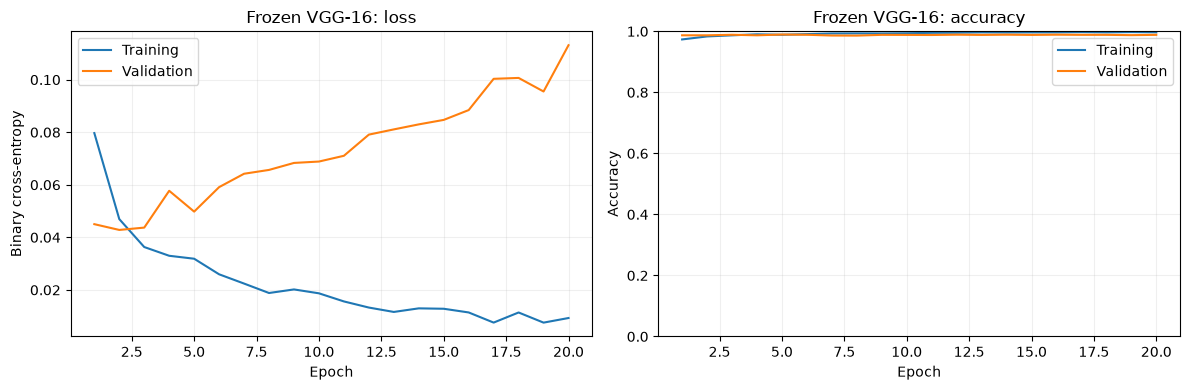

Selected epoch: 2 | Validation loss: 0.0428 | Validation accuracy: 98.70%


In [17]:
import matplotlib.pyplot as plt

result_dir = PROJECT_ROOT / "outputs" / "vgg16_frozen"

with (result_dir / "history.csv").open(
    newline="", encoding="utf-8"
) as file:
    records = list(csv.DictReader(file))

epochs = [int(row["epoch"]) for row in records]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for prefix, label in [
    ("train", "Training"),
    ("val", "Validation"),
]:
    axes[0].plot(
        epochs,
        [float(row[f"{prefix}_loss"]) for row in records],
        label=label,
    )
    axes[1].plot(
        epochs,
        [float(row[f"{prefix}_accuracy"]) for row in records],
        label=label,
    )

axes[0].set_title("Frozen VGG-16: loss")
axes[0].set_ylabel("Binary cross-entropy")
axes[1].set_title("Frozen VGG-16: accuracy")
axes[1].set_ylabel("Accuracy")
axes[1].set_ylim(0, 1)

for ax in axes:
    ax.set_xlabel("Epoch")
    ax.legend()
    ax.grid(alpha=0.2)

fig.tight_layout()
fig.savefig(result_dir / "learning_curves.png", dpi=150)
plt.show()

best = min(records, key=lambda row: float(row["val_loss"]))

print(
    f"Selected epoch: {best['epoch']} | "
    f"Validation loss: {float(best['val_loss']):.4f} | "
    f"Validation accuracy: {float(best['val_accuracy']):.2%}"
)

## Load the selected model and unfreeze block 5

In [18]:
import json
import torch
from torch import nn
from scripts.data import make_loaders

SOURCE_PATH = (
    PROJECT_ROOT / "outputs" / "vgg16_frozen" / "best.pt"
)
RUN_DIR = PROJECT_ROOT / "outputs" / "vgg16_finetuned"

if RUN_DIR.exists() and any(RUN_DIR.iterdir()):
    raise RuntimeError(
        "outputs/vgg16_finetuned already contains an experiment. "
        "Choose another RUN_DIR to avoid overwriting it."
    )

source_checkpoint = torch.load(
    SOURCE_PATH,
    map_location="cpu",
    weights_only=True,
)

model.load_state_dict(source_checkpoint["model_state_dict"])

config = dict(source_checkpoint["config"])
config.update({
    "experiment": "vgg16_finetuned",
    "feature_extractor_frozen": False,
    "frozen_blocks": [1, 2, 3, 4],
    "trainable_blocks": [5],
    "unfreeze_from": "block5_conv1",
    "unfreeze_feature_index": 24,
    "learning_rate": 1e-5,
    "epochs": 10,
    "source_checkpoint": str(SOURCE_PATH.relative_to(PROJECT_ROOT)),
    "source_epoch": source_checkpoint["epoch"],
})

EPOCHS = config["epochs"]
SEED = config["seed"]

train_loader, val_loader, _ = make_loaders(
    batch_size=config["batch_size"],
    num_workers=0,
    seed=SEED,
    augment_train=True,
)

torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Check the expected Torchvision VGG-16 structure.
assert len(model.features) == 31
assert isinstance(model.features[24], nn.Conv2d)
assert model.features[24].in_channels == 512
assert model.features[24].out_channels == 512

for index, layer in enumerate(model.features):
    for parameter in layer.parameters():
        parameter.requires_grad = (index >= 24)

for parameter in model.classifier.parameters():
    parameter.requires_grad = True

assert all(
    not p.requires_grad
    for layer in model.features[:24]
    for p in layer.parameters()
)
assert all(
    p.requires_grad
    for layer in model.features[24:]
    for p in layer.parameters()
)

criterion = nn.BCEWithLogitsLoss()

# Fresh optimizer: fine-tuning changes the trainable parameter set.
optimizer = torch.optim.RMSprop(
    [p for p in model.parameters() if p.requires_grad],
    lr=config["learning_rate"],
    alpha=config["alpha"],
    eps=config["eps"],
    momentum=config["momentum"],
    weight_decay=config["weight_decay"],
)

RUN_DIR.mkdir(parents=True, exist_ok=True)
(RUN_DIR / "config.json").write_text(
    json.dumps(config, indent=2),
    encoding="utf-8",
)

print("Loaded frozen checkpoint, epoch:", source_checkpoint["epoch"])
print("Blocks 1–4: FROZEN")
print("Block 5 and classifier: TRAINABLE")
print("Learning rate:", config["learning_rate"])
print(
    "Trainable parameters:",
    f"{sum(p.numel() for p in model.parameters() if p.requires_grad):,}",
)
print("Outputs:", RUN_DIR)

Loaded frozen checkpoint, epoch: 2
Blocks 1–4: FROZEN
Block 5 and classifier: TRAINABLE
Learning rate: 1e-05
Trainable parameters: 19,925,505
Outputs: /home/adarsha/projects/Household-Animals-Classification-Using-Deep-Learning/outputs/vgg16_finetuned


## Fine-tune and preserve the best candidate

In [19]:
import csv
import time

history = []
best_val_loss = source_checkpoint["val_loss"]

# Preserve the starting model as a valid candidate.
torch.save(
    {
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "epoch": 0,
        "best_val_loss": best_val_loss,
        "val_loss": source_checkpoint["val_loss"],
        "val_accuracy": source_checkpoint["val_accuracy"],
        "config": config,
    },
    RUN_DIR / "best.pt",
)

print(
    f"Starting validation loss: {best_val_loss:.4f} | "
    f"Accuracy: {source_checkpoint['val_accuracy']:.2%}"
)

for epoch in range(1, EPOCHS + 1):
    started = time.perf_counter()

    train_metrics = run_epoch(train_loader, training=True)
    val_metrics = run_epoch(val_loader, training=False)

    row = {
        "epoch": epoch,
        "train_loss": train_metrics["loss"],
        "train_accuracy": train_metrics["accuracy"],
        "val_loss": val_metrics["loss"],
        "val_accuracy": val_metrics["accuracy"],
        "seconds": time.perf_counter() - started,
    }
    history.append(row)

    with (RUN_DIR / "history.csv").open(
        "w", newline="", encoding="utf-8"
    ) as file:
        writer = csv.DictWriter(file, fieldnames=list(row))
        writer.writeheader()
        writer.writerows(history)

    improved = row["val_loss"] < best_val_loss

    if improved:
        best_val_loss = row["val_loss"]

    checkpoint = {
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "epoch": epoch,
        "best_val_loss": best_val_loss,
        "val_loss": row["val_loss"],
        "val_accuracy": row["val_accuracy"],
        "config": config,
    }

    torch.save(checkpoint, RUN_DIR / "last.pt")

    if improved:
        torch.save(checkpoint, RUN_DIR / "best.pt")

    print(
        f"Fine-tuning epoch {epoch:02d}/{EPOCHS} | "
        f"Train loss: {row['train_loss']:.4f}, "
        f"accuracy: {row['train_accuracy']:.2%} | "
        f"Val loss: {row['val_loss']:.4f}, "
        f"accuracy: {row['val_accuracy']:.2%} | "
        f"Time: {row['seconds']:.0f}s"
        + (" | Best checkpoint saved" if improved else ""),
        flush=True,
    )

print("\nVGG-16 fine-tuning completed.")

Starting validation loss: 0.0428 | Accuracy: 98.70%


Fine-tuning epoch 01/10 | Train loss: 0.0224, accuracy: 99.31% | Val loss: 0.0446, accuracy: 99.02% | Time: 247s


Fine-tuning epoch 02/10 | Train loss: 0.0139, accuracy: 99.52% | Val loss: 0.0438, accuracy: 98.97% | Time: 251s


Fine-tuning epoch 03/10 | Train loss: 0.0166, accuracy: 99.39% | Val loss: 0.0441, accuracy: 98.92% | Time: 251s


Fine-tuning epoch 04/10 | Train loss: 0.0136, accuracy: 99.50% | Val loss: 0.0610, accuracy: 98.75% | Time: 249s


...

Fine-tuning epoch 06/10 | Train loss: 0.0083, accuracy: 99.72% | Val loss: 0.0523, accuracy: 98.85% | Time: 249s


Fine-tuning epoch 07/10 | Train loss: 0.0064, accuracy: 99.75% | Val loss: 0.0545, accuracy: 99.02% | Time: 248s


Fine-tuning epoch 08/10 | Train loss: 0.0066, accuracy: 99.77% | Val loss: 0.0583, accuracy: 98.80% | Time: 248s


Fine-tuning epoch 09/10 | Train loss: 0.0044, accuracy: 99.84% | Val loss: 0.0650, accuracy: 98.77% | Time: 247s


Fine-tuning epoch 10/10 | Train loss: 0.0036, accuracy: 99.89% | Val loss: 0.0699, accuracy: 98.90% | Time: 247s

VGG-16 fine-tuning completed.


## Plot fine-tuning results and report selection

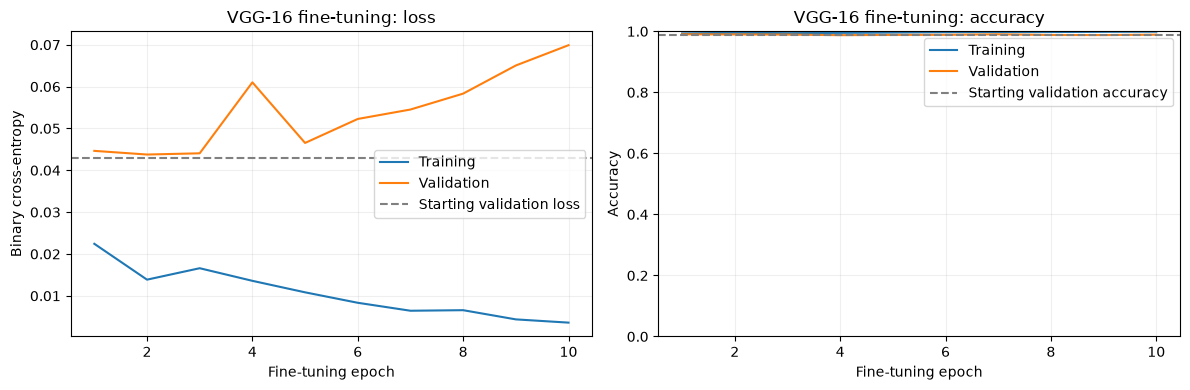

Selected fine-tuning epoch: 0
Validation loss: 0.0428
Validation accuracy: 98.70%
Fine-tuning did not improve the starting validation loss.


In [20]:
import matplotlib.pyplot as plt

result_dir = PROJECT_ROOT / "outputs" / "vgg16_finetuned"

with (result_dir / "history.csv").open(
    newline="", encoding="utf-8"
) as file:
    records = list(csv.DictReader(file))

starting = torch.load(
    PROJECT_ROOT / "outputs" / "vgg16_frozen" / "best.pt",
    map_location="cpu",
    weights_only=True,
)

selected = torch.load(
    result_dir / "best.pt",
    map_location="cpu",
    weights_only=True,
)

epochs = [int(row["epoch"]) for row in records]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for prefix, label in [
    ("train", "Training"),
    ("val", "Validation"),
]:
    axes[0].plot(
        epochs,
        [float(row[f"{prefix}_loss"]) for row in records],
        label=label,
    )
    axes[1].plot(
        epochs,
        [float(row[f"{prefix}_accuracy"]) for row in records],
        label=label,
    )

axes[0].axhline(
    starting["val_loss"],
    color="gray",
    linestyle="--",
    label="Starting validation loss",
)
axes[1].axhline(
    starting["val_accuracy"],
    color="gray",
    linestyle="--",
    label="Starting validation accuracy",
)

axes[0].set_title("VGG-16 fine-tuning: loss")
axes[0].set_ylabel("Binary cross-entropy")
axes[1].set_title("VGG-16 fine-tuning: accuracy")
axes[1].set_ylabel("Accuracy")
axes[1].set_ylim(0, 1)

for ax in axes:
    ax.set_xlabel("Fine-tuning epoch")
    ax.legend()
    ax.grid(alpha=0.2)

fig.tight_layout()
fig.savefig(result_dir / "learning_curves.png", dpi=150)
plt.show()

print("Selected fine-tuning epoch:", selected["epoch"])
print(f"Validation loss: {selected['val_loss']:.4f}")
print(f"Validation accuracy: {selected['val_accuracy']:.2%}")

if selected["epoch"] == 0:
    print("Fine-tuning did not improve the starting validation loss.")
else:
    print("Fine-tuning improved the starting validation loss.")

del starting, selected

## Prepare the test evaluation

In [21]:
import csv
import hashlib
import json

import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader
from tqdm.auto import tqdm

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support,
)

from scripts.data import AnimalDataset, MEAN, STD
from scripts.models import VGG6, VGG16Binary

EVAL_DIR = PROJECT_ROOT / "outputs" / "evaluation"
EVAL_DIR.mkdir(parents=True, exist_ok=True)

test_dataset = AnimalDataset(
    split="test",
    augment_train=False,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
    drop_last=False,
)

TEST_MANIFEST_HASH = hashlib.sha256(
    (PROJECT_ROOT / "data" / "splits" / "test.csv").read_bytes()
).hexdigest()

experiments = [
    ("vgg6_initial", "best.pt"),
    ("vgg6_regularized", "best.pt"),
    ("vgg16_frozen", "best.pt"),
    ("vgg16_finetuned", "last.pt"),
]

selection = {
    "selected_model": "vgg16_frozen",
    "checkpoint": "outputs/vgg16_frozen/best.pt",
    "selection_basis": "Lowest validation loss",
    "selected_before_test_evaluation": True,
    "fine_tuned_comparison": (
        "Final fine-tuning epoch; not the selected deployment model"
    ),
}

(EVAL_DIR / "model_selection.json").write_text(
    json.dumps(selection, indent=2),
    encoding="utf-8",
)

print("Test images:", len(test_dataset))
print("Test augmentation:", test_dataset.augmentation_enabled)
print("Selected final model:", selection["selected_model"])
print("Evaluation outputs:", EVAL_DIR)

Test images: 1002
Test augmentation: False
Selected final model: vgg16_frozen
Evaluation outputs: /home/adarsha/projects/Household-Animals-Classification-Using-Deep-Learning/outputs/evaluation


## Evaluate and save each model’s results

In [22]:
def evaluate_checkpoint(experiment, checkpoint_name):
    checkpoint_path = (
        PROJECT_ROOT / "outputs" / experiment / checkpoint_name
    )

    saved = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=True,
    )
    settings = saved["config"]

    # Verify the checkpoint uses our unchanged test split/preprocessing.
    assert (
        settings["split_manifest_sha256"]["test"]
        == TEST_MANIFEST_HASH
    ), "Test manifest has changed."

    assert settings["label_mapping"] == {"cat": 0, "dog": 1}
    assert settings["image_size"] == 224
    assert settings["normalization_mean"] == list(MEAN)
    assert settings["normalization_std"] == list(STD)

    if experiment.startswith("vgg6_"):
        eval_model = VGG6(
            image_size=settings["image_size"],
            hidden_units=settings["hidden_units"],
            dropout=settings["dropout"],
        )
    else:
        eval_model = VGG16Binary(
            hidden_units=settings["hidden_units"],
            dropout=settings["dropout"],
            pretrained=False,  # Saved checkpoint supplies all weights.
        )

    eval_model.load_state_dict(saved["model_state_dict"])
    eval_model = eval_model.to(device)
    eval_model.eval()

    loss_function = nn.BCEWithLogitsLoss(reduction="sum")

    all_labels = []
    all_predictions = []
    all_probabilities = []
    total_loss = 0.0

    with torch.inference_mode():
        for images, labels in tqdm(
            test_loader,
            desc=f"Testing {experiment}",
            leave=False,
        ):
            images = images.to(device, non_blocking=True)
            targets = labels.to(device, non_blocking=True).float()

            logits = eval_model(images)

            if not torch.isfinite(logits).all().item():
                raise RuntimeError("Non-finite predictions detected.")

            total_loss += loss_function(logits, targets).item()

            probabilities = torch.sigmoid(logits)
            predictions = (logits >= 0).long()

            all_labels.extend(labels.tolist())
            all_predictions.extend(predictions.cpu().tolist())
            all_probabilities.extend(probabilities.cpu().tolist())

    assert len(all_labels) == len(test_dataset)
    assert all_labels == [
        int(row["label"]) for row in test_dataset.rows
    ]

    precision, recall, f1, _ = precision_recall_fscore_support(
        all_labels,
        all_predictions,
        labels=[0, 1],
        average="macro",
        zero_division=0,
    )

    matrix = confusion_matrix(
        all_labels, all_predictions, labels=[0, 1]
    )

    result = {
        "experiment": experiment,
        "checkpoint": checkpoint_name,
        "checkpoint_epoch": int(saved["epoch"]),
        "test_images": len(all_labels),
        "test_loss": total_loss / len(all_labels),
        "accuracy": float(
            accuracy_score(all_labels, all_predictions)
        ),
        "macro_precision": float(precision),
        "macro_recall": float(recall),
        "macro_f1": float(f1),
        "correct": int(
            np.sum(np.array(all_labels) == np.array(all_predictions))
        ),
    }

    model_dir = EVAL_DIR / experiment
    model_dir.mkdir(parents=True, exist_ok=True)

    report = classification_report(
        all_labels,
        all_predictions,
        labels=[0, 1],
        target_names=["cat", "dog"],
        output_dict=True,
        zero_division=0,
    )

    (model_dir / "metrics.json").write_text(
        json.dumps(
            {
                **result,
                "confusion_matrix": matrix.tolist(),
                "classification_report": report,
            },
            indent=2,
        ),
        encoding="utf-8",
    )

    with (model_dir / "predictions.csv").open(
        "w", newline="", encoding="utf-8"
    ) as file:
        writer = csv.DictWriter(
            file,
            fieldnames=[
                "path",
                "true_label",
                "predicted_label",
                "dog_probability",
                "correct",
            ],
        )
        writer.writeheader()

        for row, label, prediction, probability in zip(
            test_dataset.rows,
            all_labels,
            all_predictions,
            all_probabilities,
        ):
            writer.writerow({
                "path": row["path"],
                "true_label": label,
                "predicted_label": prediction,
                "dog_probability": probability,
                "correct": label == prediction,
            })

    print(
        f"{experiment} | Epoch {saved['epoch']} | "
        f"Test accuracy: {result['accuracy']:.2%} | "
        f"Macro F1: {result['macro_f1']:.4f} | "
        f"Loss: {result['test_loss']:.4f} | "
        f"Correct: {result['correct']}/{len(all_labels)}"
    )

    del eval_model, saved
    torch.cuda.empty_cache()

    return result


results = [
    evaluate_checkpoint(experiment, checkpoint_name)
    for experiment, checkpoint_name in experiments
]

with (EVAL_DIR / "summary.csv").open(
    "w", newline="", encoding="utf-8"
) as file:
    writer = csv.DictWriter(
        file, fieldnames=list(results[0])
    )
    writer.writeheader()
    writer.writerows(results)

print("\nSaved comparison:", EVAL_DIR / "summary.csv")

vgg6_initial | Epoch 7 | Test accuracy: 87.13% | Macro F1: 0.8712 | Loss: 0.2926 | Correct: 873/1002


vgg6_regularized | Epoch 19 | Test accuracy: 92.91% | Macro F1: 0.9291 | Loss: 0.1853 | Correct: 931/1002


vgg16_frozen | Epoch 2 | Test accuracy: 98.70% | Macro F1: 0.9870 | Loss: 0.0322 | Correct: 989/1002


vgg16_finetuned | Epoch 10 | Test accuracy: 99.50% | Macro F1: 0.9950 | Loss: 0.0242 | Correct: 997/1002

Saved comparison: /home/adarsha/projects/Household-Animals-Classification-Using-Deep-Learning/outputs/evaluation/summary.csv


## Plot the confusion matrices

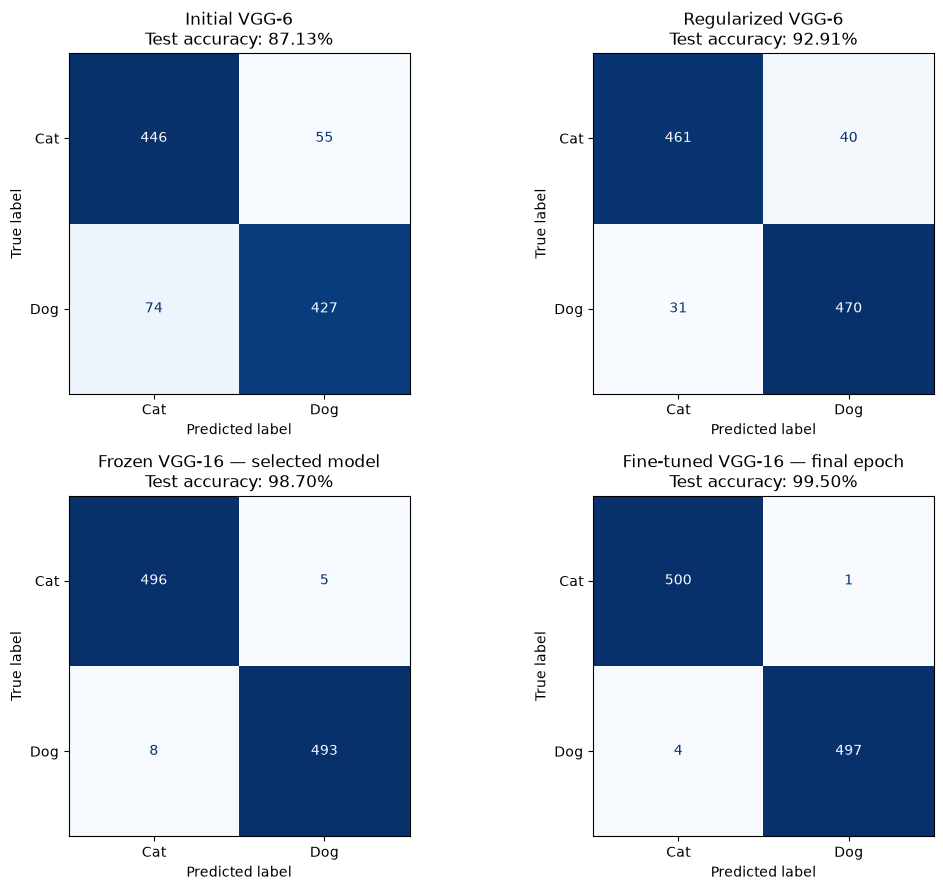

In [23]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

titles = {
    "vgg6_initial": "Initial VGG-6",
    "vgg6_regularized": "Regularized VGG-6",
    "vgg16_frozen": "Frozen VGG-16 — selected model",
    "vgg16_finetuned": "Fine-tuned VGG-16 — final epoch",
}

fig, axes = plt.subplots(2, 2, figsize=(11, 9))

for result, ax in zip(results, axes.flat):
    experiment = result["experiment"]

    metrics = json.loads(
        (
            EVAL_DIR / experiment / "metrics.json"
        ).read_text(encoding="utf-8")
    )

    display = ConfusionMatrixDisplay(
        confusion_matrix=np.array(metrics["confusion_matrix"]),
        display_labels=["Cat", "Dog"],
    )
    display.plot(
        ax=ax,
        cmap="Blues",
        colorbar=False,
        values_format="d",
    )
    ax.set_title(
        f"{titles[experiment]}\n"
        f"Test accuracy: {metrics['accuracy']:.2%}"
    )

fig.tight_layout()
fig.savefig(EVAL_DIR / "confusion_matrices.png", dpi=150)
plt.show()

## Load regularized VGG-6 and a dog image

Image: data/train/dog.10033.jpg
True label: Dog
Predicted label: Dog
Dog probability score: 0.5505


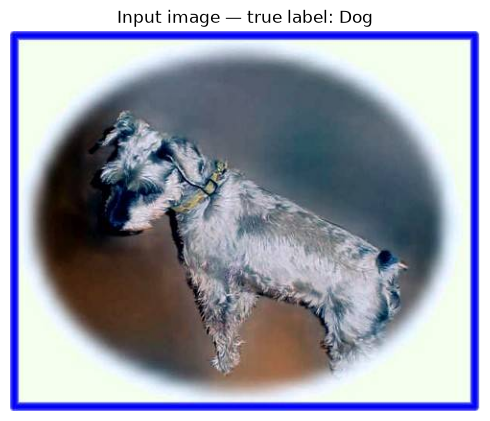

In [24]:
from PIL import Image, ImageOps
import matplotlib.pyplot as plt

from scripts.models import VGG6
from scripts.data import AnimalDataset

VIS_DIR = PROJECT_ROOT / "outputs" / "visualizations"
VIS_DIR.mkdir(parents=True, exist_ok=True)

activation_checkpoint = torch.load(
    PROJECT_ROOT / "outputs" / "vgg6_regularized" / "best.pt",
    map_location="cpu",
    weights_only=True,
)

activation_config = activation_checkpoint["config"]

activation_model = VGG6(
    image_size=activation_config["image_size"],
    hidden_units=activation_config["hidden_units"],
    dropout=activation_config["dropout"],
).to(device)

activation_model.load_state_dict(
    activation_checkpoint["model_state_dict"]
)
activation_model.eval()

visual_dataset = AnimalDataset("test", augment_train=False)

sample_index = next(
    index
    for index, row in enumerate(visual_dataset.rows)
    if int(row["label"]) == 1
)

sample_row = visual_dataset.rows[sample_index]
sample_path = PROJECT_ROOT / sample_row["path"]
sample_tensor, sample_label = visual_dataset[sample_index]

with Image.open(sample_path) as image:
    sample_image = ImageOps.exif_transpose(image).convert("RGB")
    sample_image = sample_image.copy()

with torch.inference_mode():
    sample_logit = activation_model(
        sample_tensor.unsqueeze(0).to(device)
    ).item()

dog_probability = torch.sigmoid(
    torch.tensor(sample_logit)
).item()

print("Image:", sample_row["path"])
print("True label: Dog")
print("Predicted label:", "Dog" if sample_logit >= 0 else "Cat")
print(f"Dog probability score: {dog_probability:.4f}")

fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(sample_image)
ax.set_title("Input image — true label: Dog")
ax.axis("off")
fig.tight_layout()
fig.savefig(VIS_DIR / "activation_input.png", dpi=150)
plt.show()

## Capture intermediate feature maps

In [25]:
activations = {}

# ReLU outputs immediately after convolution layers 1, 2, and 3.
layer_indices = {
    "conv1": 1,
    "conv2": 4,
    "conv3": 7,
}


def capture_activation(name):
    def hook(module, inputs, output):
        activations[name] = output.detach().cpu().clone()
    return hook


handles = []

try:
    for name, index in layer_indices.items():
        handle = activation_model.features[index].register_forward_hook(
            capture_activation(name)
        )
        handles.append(handle)

    with torch.inference_mode():
        activation_model(sample_tensor.unsqueeze(0).to(device))

finally:
    # Remove hooks so subsequent predictions do not keep recording.
    for handle in handles:
        handle.remove()

for name, maps in activations.items():
    print(name, tuple(maps.shape))

assert activations["conv1"].shape == (1, 32, 224, 224)
assert activations["conv2"].shape == (1, 64, 112, 112)
assert activations["conv3"].shape == (1, 128, 56, 56)

print("Activation shapes verified.")

conv1 (1, 32, 224, 224)
conv2 (1, 64, 112, 112)
conv3 (1, 128, 56, 56)
Activation shapes verified.


## Display and save feature-map grids

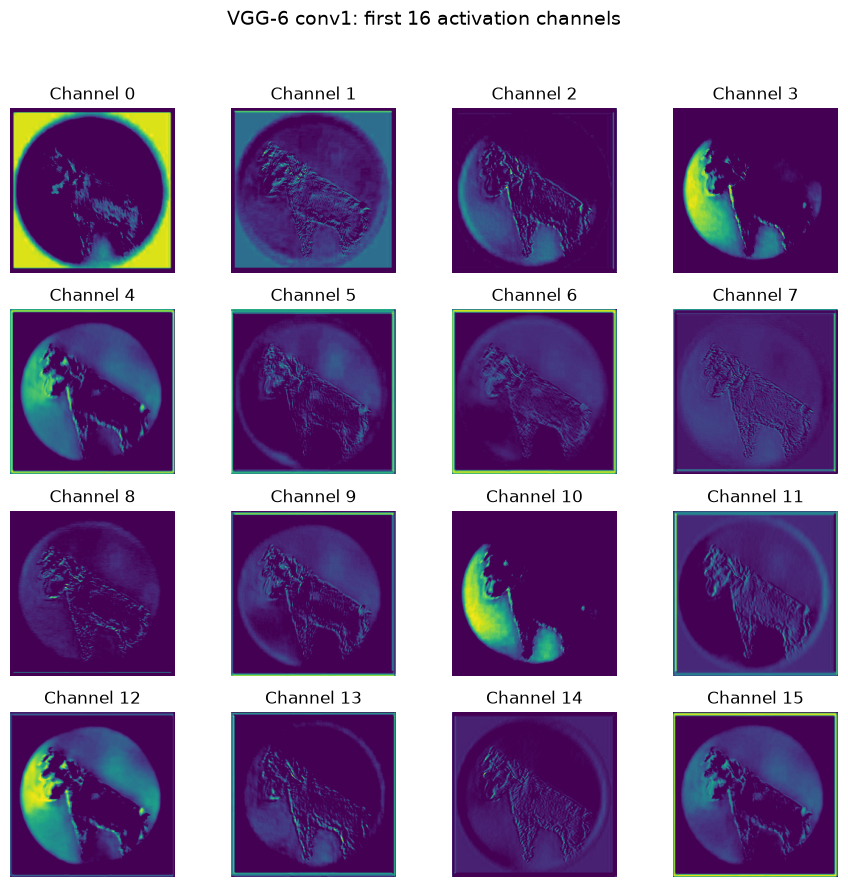

Saved: /home/adarsha/projects/Household-Animals-Classification-Using-Deep-Learning/outputs/visualizations/vgg6_conv1_activations.png


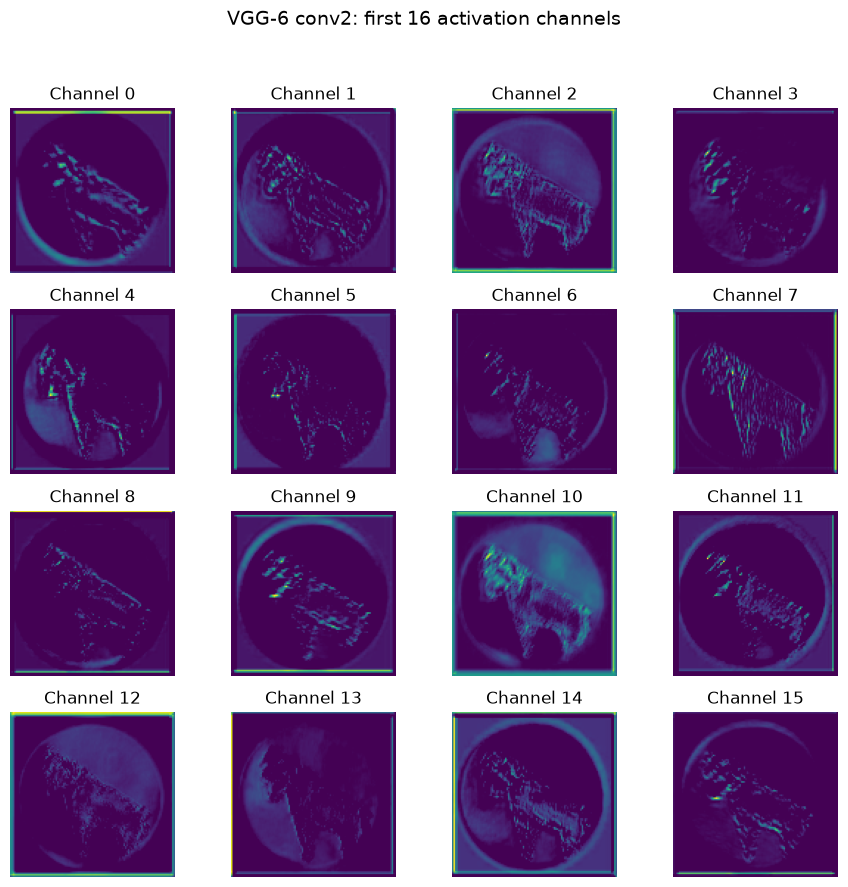

Saved: /home/adarsha/projects/Household-Animals-Classification-Using-Deep-Learning/outputs/visualizations/vgg6_conv2_activations.png


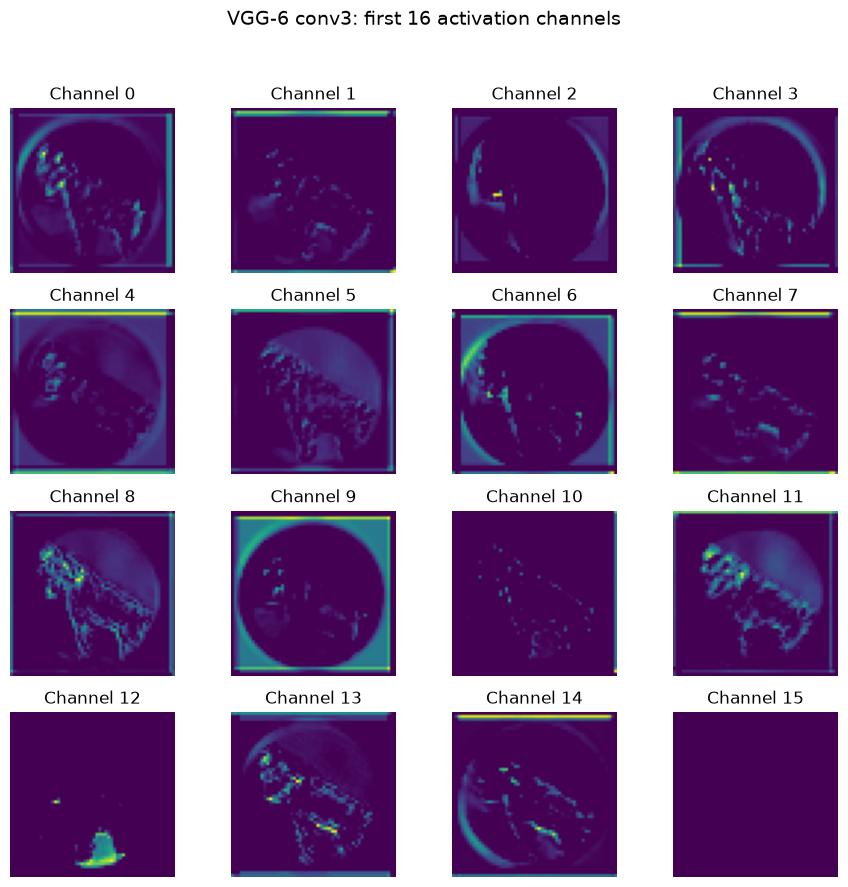

Saved: /home/adarsha/projects/Household-Animals-Classification-Using-Deep-Learning/outputs/visualizations/vgg6_conv3_activations.png


In [26]:
import numpy as np

for name, maps in activations.items():
    fig, axes = plt.subplots(4, 4, figsize=(9, 9))

    for channel, ax in enumerate(axes.flat):
        feature_map = maps[0, channel].numpy()

        minimum = float(feature_map.min())
        maximum = float(feature_map.max())
        span = maximum - minimum

        if span > 0:
            display_map = (feature_map - minimum) / span
        else:
            display_map = np.zeros_like(feature_map)

        ax.imshow(
            display_map,
            cmap="viridis",
            vmin=0,
            vmax=1,
        )
        ax.set_title(f"Channel {channel}")
        ax.axis("off")

    fig.suptitle(
        f"VGG-6 {name}: first 16 activation channels",
        fontsize=14,
    )
    fig.tight_layout(rect=(0, 0, 1, 0.95))

    output_path = VIS_DIR / f"vgg6_{name}_activations.png"
    fig.savefig(output_path, dpi=150)
    plt.show()

    print("Saved:", output_path)

## Load the selected VGG-16 for explanations

In [27]:
from scripts.models import VGG16Binary
from scripts.explain import binary_gradcam

heatmap_checkpoint = torch.load(
    PROJECT_ROOT / "outputs" / "vgg16_frozen" / "best.pt",
    map_location="cpu",
    weights_only=True,
)

heatmap_config = heatmap_checkpoint["config"]

heatmap_model = VGG16Binary(
    hidden_units=heatmap_config["hidden_units"],
    dropout=heatmap_config["dropout"],
    pretrained=False,
).to(device)

heatmap_model.load_state_dict(
    heatmap_checkpoint["model_state_dict"]
)
heatmap_model.eval()

# Torchvision VGG-16: final convolution is index 28,
# followed by ReLU at index 29 and pooling at index 30.
target_layer = heatmap_model.features[29]

assert isinstance(target_layer, nn.ReLU)

print("Model: selected frozen VGG-16")
print("Checkpoint epoch:", heatmap_checkpoint["epoch"])
print("Target: block5_conv3 ReLU output")

Model: selected frozen VGG-16
Checkpoint epoch: 2
Target: block5_conv3 ReLU output


## Generate a heatmap for the same dog image

In [28]:
gradcam_result = binary_gradcam(
    model=heatmap_model,
    image_tensor=sample_tensor.unsqueeze(0).to(device),
    target_layer=target_layer,
    target_class=None,
)

heatmap = gradcam_result["heatmap"]

assert heatmap.shape == (224, 224)
assert np.isfinite(heatmap).all()
assert heatmap.min() >= 0
assert heatmap.max() <= 1.00001

class_names = {0: "Cat", 1: "Dog"}

print("Image:", sample_row["path"])
print("True label:", class_names[sample_label])
print(
    "Predicted class:",
    class_names[gradcam_result["predicted_class"]],
)
print(
    "Explained class:",
    class_names[gradcam_result["target_class"]],
)
print(
    "Dog probability score:",
    f"{gradcam_result['dog_probability']:.4f}",
)
print("Heatmap shape:", heatmap.shape)

if not gradcam_result["has_positive_signal"]:
    print("No positive Grad-CAM signal for this target.")
else:
    print("Grad-CAM computation passed.")

Image: data/train/dog.10033.jpg
True label: Dog
Predicted class: Dog
Explained class: Dog
Dog probability score: 0.9902
Heatmap shape: (224, 224)
Grad-CAM computation passed.


## Display and save the heatmap

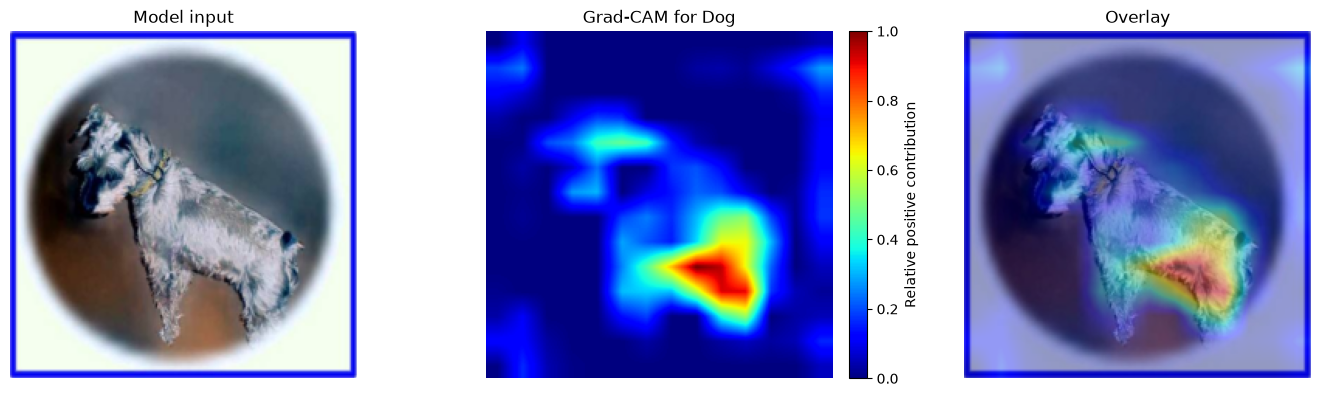

Saved: /home/adarsha/projects/Household-Animals-Classification-Using-Deep-Learning/outputs/visualizations/vgg16_dog_gradcam.png


In [29]:
# Match the direct resizing used by scripts/data.py.
display_image = sample_image.resize(
    (224, 224),
    resample=Image.Resampling.BILINEAR,
)
display_array = np.asarray(display_image).astype(np.float32) / 255.0

explained_name = class_names[gradcam_result["target_class"]]

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].imshow(display_array)
axes[0].set_title("Model input")

heatmap_plot = axes[1].imshow(
    heatmap,
    cmap="jet",
    vmin=0,
    vmax=1,
)
axes[1].set_title(f"Grad-CAM for {explained_name}")

axes[2].imshow(display_array)
axes[2].imshow(
    heatmap,
    cmap="jet",
    vmin=0,
    vmax=1,
    alpha=0.4,
)
axes[2].set_title("Overlay")

for ax in axes:
    ax.axis("off")

fig.colorbar(
    heatmap_plot,
    ax=axes[1],
    fraction=0.046,
    pad=0.04,
    label="Relative positive contribution",
)

fig.tight_layout()

output_path = VIS_DIR / "vgg16_dog_gradcam.png"
fig.savefig(output_path, dpi=150)
plt.show()

np.save(VIS_DIR / "vgg16_dog_gradcam.npy", heatmap)

metadata = {
    "image": sample_row["path"],
    "model_checkpoint": "outputs/vgg16_frozen/best.pt",
    "method": "Grad-CAM",
    "target_layer": "features.29",
    "true_label": int(sample_label),
    "predicted_class": gradcam_result["predicted_class"],
    "explained_class": gradcam_result["target_class"],
    "dog_probability": gradcam_result["dog_probability"],
    "has_positive_signal": gradcam_result["has_positive_signal"],
}

(VIS_DIR / "vgg16_dog_gradcam.json").write_text(
    json.dumps(metadata, indent=2),
    encoding="utf-8",
)

print("Saved:", output_path)

## Select the examples

In [30]:
prediction_file = (
    PROJECT_ROOT
    / "outputs"
    / "evaluation"
    / "vgg16_frozen"
    / "predictions.csv"
)

with prediction_file.open(newline="", encoding="utf-8") as file:
    prediction_rows = list(csv.DictReader(file))

correct_cat = next(
    row for row in prediction_rows
    if int(row["true_label"]) == 0
    and int(row["predicted_label"]) == 0
)

errors = [
    row for row in prediction_rows
    if int(row["true_label"]) != int(row["predicted_label"])
]

if not errors:
    raise RuntimeError("No misclassified images found.")

explanation_examples = [
    ("correct_cat", correct_cat),
    ("first_error", errors[0]),
]

path_to_index = {
    row["path"]: index
    for index, row in enumerate(visual_dataset.rows)
}

print("Total selected-model errors:", len(errors))

for name, row in explanation_examples:
    print(
        f"{name}: {row['path']} | "
        f"True: {class_names[int(row['true_label'])]} | "
        f"Predicted: {class_names[int(row['predicted_label'])]}"
    )

Total selected-model errors: 13
correct_cat: data/train/cat.10004.jpg | True: Cat | Predicted: Cat
first_error: data/train/cat.12393.jpg | True: Cat | Predicted: Dog


## Generate and save both explanations

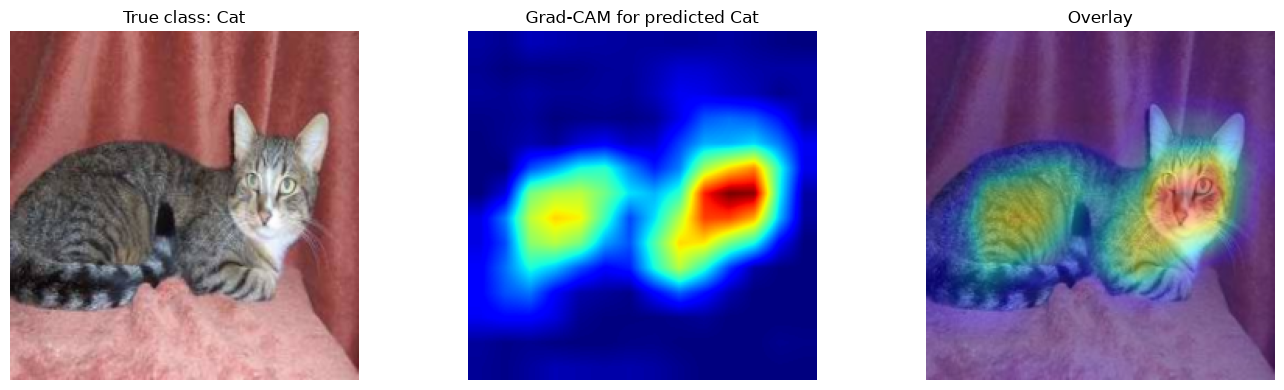

Saved: /home/adarsha/projects/Household-Animals-Classification-Using-Deep-Learning/outputs/visualizations/vgg16_correct_cat_gradcam.png
Dog probability score: 0.0000


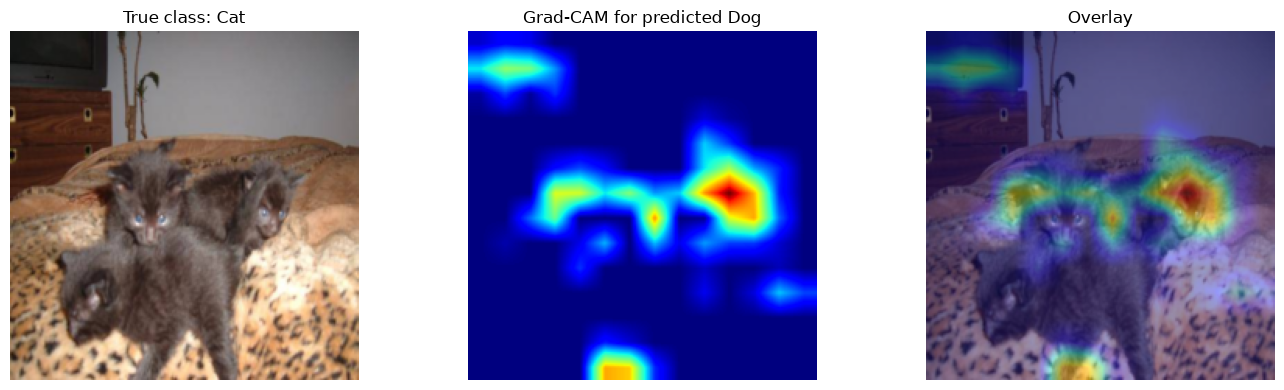

Saved: /home/adarsha/projects/Household-Animals-Classification-Using-Deep-Learning/outputs/visualizations/vgg16_first_error_gradcam.png
Dog probability score: 0.9622


In [31]:
for name, row in explanation_examples:
    index = path_to_index[row["path"]]
    image_tensor, true_label = visual_dataset[index]

    image_path = PROJECT_ROOT / row["path"]

    with Image.open(image_path) as image:
        image = ImageOps.exif_transpose(image).convert("RGB")
        display_image = image.resize(
            (224, 224),
            resample=Image.Resampling.BILINEAR,
        )

    display_array = (
        np.asarray(display_image).astype(np.float32) / 255.0
    )

    explanation = binary_gradcam(
        model=heatmap_model,
        image_tensor=image_tensor.unsqueeze(0).to(device),
        target_layer=target_layer,
        target_class=None,
    )

    predicted_label = explanation["predicted_class"]

    assert predicted_label == int(row["predicted_label"]), (
        "Prediction differs from saved evaluation. "
        "Check the model checkpoint and preprocessing."
    )

    heatmap = explanation["heatmap"]

    fig, axes = plt.subplots(1, 3, figsize=(14, 4))

    axes[0].imshow(display_array)
    axes[0].set_title(f"True class: {class_names[true_label]}")

    axes[1].imshow(heatmap, cmap="jet", vmin=0, vmax=1)
    axes[1].set_title(
        f"Grad-CAM for predicted {class_names[predicted_label]}"
    )

    axes[2].imshow(display_array)
    axes[2].imshow(
        heatmap,
        cmap="jet",
        vmin=0,
        vmax=1,
        alpha=0.4,
    )
    axes[2].set_title("Overlay")

    for ax in axes:
        ax.axis("off")

    fig.tight_layout()

    figure_path = VIS_DIR / f"vgg16_{name}_gradcam.png"
    fig.savefig(figure_path, dpi=150)
    plt.show()
    plt.close(fig)

    np.save(VIS_DIR / f"vgg16_{name}_gradcam.npy", heatmap)

    metadata = {
        "image": row["path"],
        "model_checkpoint": "outputs/vgg16_frozen/best.pt",
        "method": "Grad-CAM",
        "target_layer": "features.29",
        "true_label": int(true_label),
        "predicted_class": int(predicted_label),
        "explained_class": explanation["target_class"],
        "dog_probability": explanation["dog_probability"],
        "has_positive_signal": explanation["has_positive_signal"],
    }

    (VIS_DIR / f"vgg16_{name}_gradcam.json").write_text(
        json.dumps(metadata, indent=2),
        encoding="utf-8",
    )

    print("Saved:", figure_path)
    print(
        f"Dog probability score: "
        f"{explanation['dog_probability']:.4f}"
    )

    if not explanation["has_positive_signal"]:
        print("No positive Grad-CAM signal for this target.")